# PydanticAI together with Pydantic Models

In [1]:
from model import nvidia_model
from pydantic_ai import Agent

employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet"
    """
        name: "Bertil",
        age: 40,
        salary: 35000,
        role: "IT-supporter",
        ort: "Göteborg"
    """
    )

result = await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm ")
print(result.output)

                 pydantic-ai v2.62.0 • Python 3.13.7

      / \        agent: employee_simulator • model: openai:nvidia/nemotron-3.5-super-vl-120b-a12b
     /   \         tools: 0 • capabilities: 0
   /___.___\
  /    |    \    observability: off — see every model and tool call live, with cost
/      |      \    set it up free with Pydantic Logfire: uvx logfire-cli wizard --task pydantic-ai
`---.._|_..---'    or use any OpenTelemetry backend: https://pydantic.dev/docs/ai/logfire/#otel

                 goes away once observability is on — or PYDANTIC_AI_NO_BANNER=1


name: "Erik Nilsson",
age: 34,
salary: 54000,
role: "Data Engineer",
ort: "Stockholm"


## Force a structured output using pydantic

In [2]:
from pydantic import BaseModel, Field


class EmployeeModel(BaseModel):
    name: str = Field(
        description="för och efternamn, inte jättelångt, svenska eller internationella namn"
    )
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(
        description="lön mellan 30k-60k, ju mer senior position, desto högre lön",
        ge=30_000,
        lt=60_000,
    )
    role: str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(
    name="Bertil",
    age=40,
    salary=30000,
    role="IT supporter",
    description="Hjälper folk med IT",
)

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT supporter', description='Hjälper folk med IT')

In [3]:
employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige",
)

result = await employee_simulator.run("Ge mig en data engineer i stockholm")

result.output

'Här är en realistisk simulering av en **data engineer verksam i Stockholm** (persona i första person).\n\n---\n\n### Erik Sjöberg, 32 år  \n**Roll:** Senior Data Engineer  \n**Bor:** Södermalm, Stockholm  \n**Arbetsgivare:** Ett svenskt fintech-scale-up med ca 200 anställda, kontoret i centrala Stockholm  \n**Utbildning:** Civilingenjör i datateknik, KTH Royal Institute of Technology\n\n#### Teknisk stack\n- **Språk:** Python (pandas, polars, great_expectations), SQL (avancerat), lite Scala  \n- **Orkestrering:** Apache Airflow, Google Cloud Composer  \n- **DWH / ETL:** BigQuery, dbt, Snowflake (grundläggande kunskap)  \n- **Moln:** GCP (primärt), lite AWS  \n- **IaC / CI/CD:** Terraform, Docker, GitHub Actions, Git  \n- **Fokus:** Datakvalitet, datamodellering (Kimball/Data Vault), API:er och pipelines mellan produktionsdatabaser (PostgreSQL) och datalager\n\n#### En vanlig arbetsdag\n- **09:30:** Stand-up (på engelska, teamet är internationellt med kollegor i Malmö, Berlin och Stock

In [4]:
result = await employee_simulator.run(
    "Ge mig en data engineer i stockholm", output_type=EmployeeModel
)
result

AgentRunResult(output=EmployeeModel(name='Erik Johansson', age=32, salary=48000, role='Data Engineer', description='Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa, bygga och underhålla skalbara datapipelines. Han har erfarenhet av molntjänster som Azure och GCP samt verktyg som Airflow, dbt och SQL.'))

In [5]:
employee2 = result.output
employee2

EmployeeModel(name='Erik Johansson', age=32, salary=48000, role='Data Engineer', description='Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa, bygga och underhålla skalbara datapipelines. Han har erfarenhet av molntjänster som Azure och GCP samt verktyg som Airflow, dbt och SQL.')

In [6]:
type(employee2)

__main__.EmployeeModel

In [7]:
employee2.name + " är cool"

'Erik Johansson är cool'

In [8]:
employee2.salary

48000

In [9]:
employee2.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [10]:
employee2.__dict__.values()

dict_values(['Erik Johansson', 32, 48000, 'Data Engineer', 'Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa, bygga och underhålla skalbara datapipelines. Han har erfarenhet av molntjänster som Azure och GCP samt verktyg som Airflow, dbt och SQL.'])

In [11]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Erik Johansson
age: 32
salary: 48000
role: Data Engineer
description: Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa, bygga och underhålla skalbara datapipelines. Han har erfarenhet av molntjänster som Azure och GCP samt verktyg som Airflow, dbt och SQL.


## Simulate many employess

In [12]:
result = await employee_simulator.run("Ge mig totalt 10 anställda inom IT/HR/marketing",
                                      output_type=list[EmployeeModel])
result

AgentRunResult(output=[EmployeeModel(name='Emma Andersson', age=34, salary=48000, role='IT-säkerhetsspecialist', description='Arbetar med att skydda företagets nätverk och data från intrång och säkerhetshot. Genomför regelbundna riskanalyser och säkerhetsutbildningar för personalen.'), EmployeeModel(name='Johan Svensson', age=27, salary=33000, role='IT-supporttekniker', description='Hjälper kollegor med datorproblem, programvaruinstallationer och nätverksanslutningar. Ansvarar även för att underhålla företagets hårdvarulager.'), EmployeeModel(name='Lisa Berg', age=41, salary=56000, role='IT-projektledare', description='Ledder tekniska projekt från planering till implementation och säkerställer att deadlines och budgetar hålls. Fungerar som länk mellan teknikavdelningen och övriga verksamheten.'), EmployeeModel(name='Oskar Nilsson', age=30, salary=38000, role='HR-specialist', description='Handlar om arbetsavtal, löneadministration och arbetsmiljöfrågor för de anställda. Stödjer cheferna

In [13]:
employees = result.output

employees


[EmployeeModel(name='Emma Andersson', age=34, salary=48000, role='IT-säkerhetsspecialist', description='Arbetar med att skydda företagets nätverk och data från intrång och säkerhetshot. Genomför regelbundna riskanalyser och säkerhetsutbildningar för personalen.'),
 EmployeeModel(name='Johan Svensson', age=27, salary=33000, role='IT-supporttekniker', description='Hjälper kollegor med datorproblem, programvaruinstallationer och nätverksanslutningar. Ansvarar även för att underhålla företagets hårdvarulager.'),
 EmployeeModel(name='Lisa Berg', age=41, salary=56000, role='IT-projektledare', description='Ledder tekniska projekt från planering till implementation och säkerställer att deadlines och budgetar hålls. Fungerar som länk mellan teknikavdelningen och övriga verksamheten.'),
 EmployeeModel(name='Oskar Nilsson', age=30, salary=38000, role='HR-specialist', description='Handlar om arbetsavtal, löneadministration och arbetsmiljöfrågor för de anställda. Stödjer cheferna i personalrelatera

In [15]:
salary = 0
for employee in employees:
    salary += employee.salary

salary/len(employees)

44300.0

In [16]:
salaries = [e.salary for e in result.output]
sum(salaries) / len(salaries)

44300.0

## Convert to dataframe

In [17]:
employees[0].model_dump()

{'name': 'Emma Andersson',
 'age': 34,
 'salary': 48000,
 'role': 'IT-säkerhetsspecialist',
 'description': 'Arbetar med att skydda företagets nätverk och data från intrång och säkerhetshot. Genomför regelbundna riskanalyser och säkerhetsutbildningar för personalen.'}

In [18]:
[employee.model_dump() for employee in employees]

[{'name': 'Emma Andersson',
  'age': 34,
  'salary': 48000,
  'role': 'IT-säkerhetsspecialist',
  'description': 'Arbetar med att skydda företagets nätverk och data från intrång och säkerhetshot. Genomför regelbundna riskanalyser och säkerhetsutbildningar för personalen.'},
 {'name': 'Johan Svensson',
  'age': 27,
  'salary': 33000,
  'role': 'IT-supporttekniker',
  'description': 'Hjälper kollegor med datorproblem, programvaruinstallationer och nätverksanslutningar. Ansvarar även för att underhålla företagets hårdvarulager.'},
 {'name': 'Lisa Berg',
  'age': 41,
  'salary': 56000,
  'role': 'IT-projektledare',
  'description': 'Ledder tekniska projekt från planering till implementation och säkerställer att deadlines och budgetar hålls. Fungerar som länk mellan teknikavdelningen och övriga verksamheten.'},
 {'name': 'Oskar Nilsson',
  'age': 30,
  'salary': 38000,
  'role': 'HR-specialist',
  'description': 'Handlar om arbetsavtal, löneadministration och arbetsmiljöfrågor för de anstäl

In [23]:
import pandas as pd
pd.DataFrame([employee.model_dump() for employee in employees])

,name,age,salary,role,description
0,Emma Andersson,34,48000,IT-säkerhetsspecialist,Arbetar med att skydda företagets nätverk och ...
1,Johan Svensson,27,33000,IT-supporttekniker,"Hjälper kollegor med datorproblem, programvaru..."
2,Lisa Berg,41,56000,IT-projektledare,Ledder tekniska projekt från planering till im...
3,Oskar Nilsson,30,38000,HR-specialist,"Handlar om arbetsavtal, löneadministration och..."
4,Sofia Eriksson,44,54000,HR-chef,Ansvarar för hela HR-funktionen och strategisk...
5,Noah Danielsson,28,35000,Rekryteringskonsult,Identifierar och intervjuar kandidater för led...
6,Mia Holm,29,34000,Marknadskoordinator,"Koordinerar marknadsföringskampanjer, event oc..."
7,Victor Lindqvist,35,42000,Digital marknadsförare,Optimerar företagets närvaro i sociala medier ...
8,Helena Pettersson,50,58000,Marknadschef,Utvecklar och driver företagets övergripande m...
9,Amir Hassan,37,45000,HR-systemansvarig (HRIS),Förvaltar och utvecklar företagets HR-system o...


In [25]:
df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Emma Andersson,34,48000,IT-säkerhetsspecialist,Arbetar med att skydda företagets nätverk och ...
1,Johan Svensson,27,33000,IT-supporttekniker,"Hjälper kollegor med datorproblem, programvaru..."
2,Lisa Berg,41,56000,IT-projektledare,Ledder tekniska projekt från planering till im...
3,Oskar Nilsson,30,38000,HR-specialist,"Handlar om arbetsavtal, löneadministration och..."
4,Sofia Eriksson,44,54000,HR-chef,Ansvarar för hela HR-funktionen och strategisk...


In [27]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

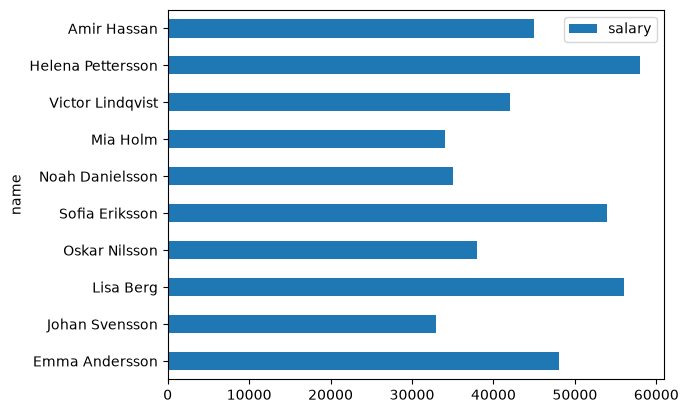

In [28]:
df.plot(kind = "barh", x = "name", y = "salary")